# Call Center Scheduling
*for instructions see HW1 in BRUTE*

In [5]:
!pip install gurobipy
%matplotlib inline
import gurobipy as g
import matplotlib.pyplot as plt

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

/home/jirkadolezal/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [7]:
d = [6, 6, 6, 6, 6, 8, 9, 12, 18, 22, 25, 21, 21, 20, 18, 21, 21, 24, 24, 18, 18, 18, 12, 8]

In [11]:
model = g.Model()

x = model.addVars(len(d), vtype=g.GRB.INTEGER, lb=0)

for i in range(len(d)):
    model.addConstr(
        g.quicksum(x[j % len(d)] for j in range (i-7, i+1)) >= d[i]
)

model.setObjective(x.sum(), sense=g.GRB.MINIMIZE)
model.optimize()   

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Pop!_OS 24.04 LTS")

CPU model: AMD Ryzen 7 7840HS with Radeon 780M Graphics, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 8 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 24 rows, 24 columns and 192 nonzeros (Min)
Model fingerprint: 0x71dbed7a
Model has 24 linear objective coefficients
Variable types: 0 continuous, 24 integer (0 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [6e+00, 2e+01]

Found heuristic solution: objective 58.0000000
Presolve time: 0.00s
Presolved: 24 rows, 24 columns, 192 nonzeros
Variable types: 0 continuous, 24 integer (0 binary)

Root relaxation: objective 5.500000e+01, 14 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | I

In [19]:
model = g.Model()

x = model.addVars(len(d), vtype=g.GRB.INTEGER, lb=0)

z = model.addVars(len(d), vtype=g.GRB.INTEGER, lb=0)

for i in range(len(d)):
    model.addConstr(d[i] - g.quicksum(x[j % len(d)] for j in range (i-7, i+1)) <= z[i])
    model.addConstr(   g.quicksum(x[j % len(d)] for j in range (i-7, i+1))  - d[i]  <= z[i])
    model.addConstr(z[i] >= 0)

model.setObjective(z.sum(), sense=g.GRB.MINIMIZE)
model.optimize()   

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Pop!_OS 24.04 LTS")

CPU model: AMD Ryzen 7 7840HS with Radeon 780M Graphics, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 8 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 72 rows, 48 columns and 456 nonzeros (Min)
Model fingerprint: 0xdfddf4a8
Model has 24 linear objective coefficients
Variable types: 0 continuous, 48 integer (0 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [6e+00, 2e+01]

Found heuristic solution: objective 368.0000000
Presolve removed 24 rows and 0 columns
Presolve time: 0.00s
Presolved: 48 rows, 48 columns, 432 nonzeros
Variable types: 0 continuous, 48 integer (0 binary)

Root relaxation: objective 2.800000e+01, 31 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Dept

In [ ]:
import sys
import gurobipy as g

with open(sys.argv[1], "r") as f:
    d = [int(v) for v in f.readline().split()]
    e = [int(v) for v in f.readline().split()]
    D = int(f.readline().strip())
    
model = g.Model()

#D = 2
#e = [3, 3, 3, 3, 3, 4, 4, 6, 9, 11, 12, 10, 10, 10, 9, 10, 10, 12, 12, 9, 9, 9, 6, 4]
week = (5*d + 2*e)
x = model.addVars(168, vtype=g.GRB.INTEGER, lb=0)

z = model.addVars(168, vtype=g.GRB.INTEGER, lb=0)

for i in range(168):
    model.addConstr(week[i] - g.quicksum(x[j % 168] for j in range (i-7, i+1)) <= z[i])
    model.addConstr(   g.quicksum(x[j % 168] for j in range (i-7, i+1))  - week[i]  <= z[i])
    model.addConstr(z[i] >= 0)
    model.addConstr(week[i] - g.quicksum(x[j % 168] for j in range (i-7, i+1)) <= D)
    

model.setObjective(z.sum(), sense=g.GRB.MINIMIZE)
model.optimize()   


with open(sys.argv[2], "w") as f:
    f.write(f"{int(round(model.ObjVal))}\n")
    f.write(" ".join(str(int(round(x[i].X))) for i in range(168)) + "\n")

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Pop!_OS 24.04 LTS")

CPU model: AMD Ryzen 7 7840HS with Radeon 780M Graphics, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 8 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 672 rows, 336 columns and 4536 nonzeros (Min)
Model fingerprint: 0x7fb19862
Model has 168 linear objective coefficients
Variable types: 0 continuous, 336 integer (0 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 2e+01]

Found heuristic solution: objective 870.0000000
Presolve removed 168 rows and 0 columns
Presolve time: 0.00s
Presolved: 504 rows, 336 columns, 4368 nonzeros
Variable types: 0 continuous, 336 integer (0 binary)

Root relaxation: objective 2.320000e+02, 434 iterations, 0.01 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |

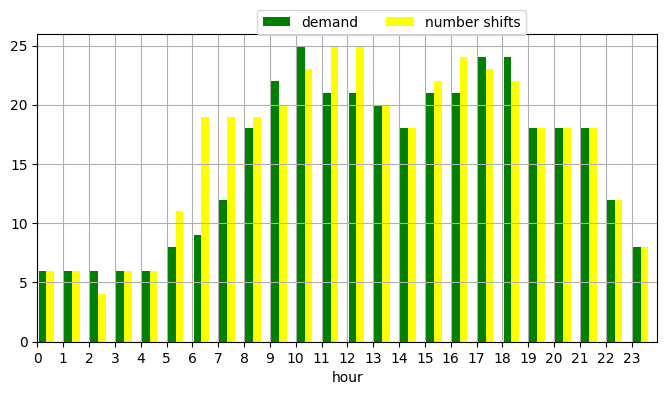

In [24]:
def plot_shifts(x_start):
    num_shifts = [sum([x_start[k % 24] for k in range(i-7, i+1)]) for i in range(24)]
    margin = 0.2
    width = 0.3
    plt.figure(figsize=(8, 4))
    plt.bar([h + margin for h in range(24)], d, width=width, color='green')
    plt.bar([h + margin + width for h in range(24)], num_shifts, width=width, color='yellow')
    plt.xlabel("hour")
    plt.legend(['demand', 'number shifts'], ncol=2, bbox_to_anchor=(0.8, 1.1))
    plt.xlim(0, 24)
    plt.ylim(0, max(num_shifts + d) + 1)
    plt.xticks(range(24), [i % 24 for i in range(24)])
    plt.grid()
    plt.show()

plot_shifts([x[i].x for i in range(24)])